In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score, ConfusionMatrixDisplay

d = np.load("../data/processed/beats.npz")
CLASSES = ["N", "S", "V", "F"]

def drop_q(X, y, rr, g):
    m = y != 4          # برچسب ۴ یعنی Q
    return X[m], y[m], rr[m], g[m]

X_train, y_train, rr_train, g_train = drop_q(d["X_train"], d["y_train"], d["rr_train"], d["g_train"])
X_test,  y_test,  rr_test,  g_test  = drop_q(d["X_test"],  d["y_test"],  d["rr_test"],  d["g_test"])

print(X_train.shape, X_test.shape)

(50969, 200) (49661, 200)


In [7]:
def rr_features(rr, g):
    prev_rr = rr[:, 0].astype(float)
    next_rr = rr[:, 1].astype(float)

    # میانه‌ی فاصله‌ی R-R هر بیمار، برای اینکه ببینیم این ضربان نسبت به ریتم معمولِ خود بیمار چقدر زود یا دیر اومده
    med_rr = np.zeros_like(prev_rr)
    for rec in np.unique(g):
        m = g == rec
        med_rr[m] = np.median(prev_rr[m])

    return np.column_stack([
        prev_rr, next_rr,
        prev_rr / next_rr,
        prev_rr / med_rr,
        next_rr / med_rr,
    ])

In [8]:
R = 90   # جای R-peak توی هر تکه‌ی ۲۰۰ نمونه‌ای

def morph_features(X):
    X = X - np.median(X, axis=1, keepdims=True)    # حذف آفست

    peak   = X.max(axis=1)
    trough = X.min(axis=1)
    p2p    = peak - trough
    amp_r  = X[:, R]
    t_peak   = X.argmax(axis=1) - R
    t_trough = X.argmin(axis=1) - R

    thr   = 0.3 * np.abs(X).max(axis=1, keepdims=True)
    width = (np.abs(X[:, R-40:R+40]) > thr).sum(axis=1)   # تخمینی از پهنای QRS

    energy = (X ** 2).sum(axis=1)
    area   = np.abs(X).sum(axis=1)
    sd     = X.std(axis=1)
    sk     = skew(X, axis=1)
    ku     = kurtosis(X, axis=1)

    shape = X[:, ::5] / (p2p[:, None] + 1e-8)   # شکل ضربان با ۴۰ نقطه، نرمال‌شده

    return np.column_stack([amp_r, peak, trough, p2p, t_peak, t_trough,
                            width, energy, area, sd, sk, ku, shape])

In [9]:
F_train = np.hstack([rr_features(rr_train, g_train), morph_features(X_train)])
F_test  = np.hstack([rr_features(rr_test,  g_test),  morph_features(X_test)])
print(F_train.shape, F_test.shape)    # باید ۵۶ ستون باشه

(50969, 57) (49661, 57)


In [10]:
dummy = DummyClassifier(strategy="most_frequent").fit(F_train, y_train)
print(classification_report(y_test, dummy.predict(F_test),
                            target_names=CLASSES, zero_division=0))

              precision    recall  f1-score   support

           N       0.89      1.00      0.94     44218
           S       0.00      0.00      0.00      1836
           V       0.00      0.00      0.00      3219
           F       0.00      0.00      0.00       388

    accuracy                           0.89     49661
   macro avg       0.22      0.25      0.24     49661
weighted avg       0.79      0.89      0.84     49661



In [11]:
rf = RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=42)
rf.fit(F_train, y_train)
pred = rf.predict(F_test)

print(classification_report(y_test, pred, target_names=CLASSES, digits=3))
print("macro F1:", round(f1_score(y_test, pred, average="macro"), 3))

              precision    recall  f1-score   support

           N      0.948     0.998     0.972     44218
           S      0.568     0.011     0.022      1836
           V      0.957     0.905     0.930      3219
           F      0.077     0.008     0.014       388

    accuracy                          0.948     49661
   macro avg      0.637     0.480     0.485     49661
weighted avg      0.928     0.948     0.927     49661

macro F1: 0.485


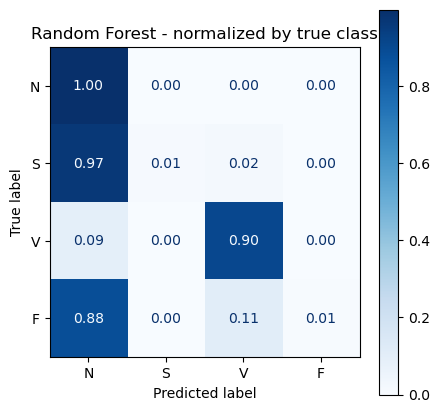

In [12]:
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=CLASSES,
    normalize="true", values_format=".2f", cmap="Blues", ax=ax)
plt.title("Random Forest - normalized by true class")
plt.show()